# Banknote dimensions

Which banknotes exhibit the greatest size differences between denominations? Which are the largest overall?

Banknote dimensions differ widely across countries.

The size of a banknote impacts its practicality. Uniform dimensions enhance durability by ensuring a snug wallet fit, while also enabling vending machines and ATMs to process them seamlessly. Conversely, varied sizes assist the visually impaired in distinguishing denominations, though smaller notes can pose challenges for machine sorting and counting.

Striking a balance between these considerations is essential in currency design.

The file `banknote-dimensions.csv` shows the `length` and `width` in millimeters for 42 currencies. This dataset spans all 22 subregions and sub-subregions of the world, as defined by the United Nations Statistics Division's geoscheme.

In [1]:
# FOR GOOGLE COLAB ONLY.
# Uncomment and run the code below. A dialog will appear to upload files.
# Upload 'banknote-dimensions.csv'.

# from google.colab import files
# uploaded = files.upload()

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option

df = pd.read_csv('banknote-dimensions.csv')
df

,currency,code,value,length,width
0,Argentine Peso,ARS,2,155.0,65.0
1,Argentine Peso,ARS,5,155.0,65.0
2,Argentine Peso,ARS,10,155.0,65.0
3,Argentine Peso,ARS,20,155.0,65.0
4,Argentine Peso,ARS,50,155.0,65.0
...,...,...,...,...,...
245,West African Franc,XOF,500,114.0,60.0
246,West African Franc,XOF,1000,125.0,66.0
247,West African Franc,XOF,2000,130.0,65.0
248,West African Franc,XOF,5000,140.0,74.0


In [11]:
# longest and shortest banknotes for each currency
# modify the code below if you are more interested in width
length = df.groupby(['currency']).agg(max=('length', 'max'), min=('length', 'min')).reset_index()
length['diff'] = length['max'] - length['min']
length.head()

,currency,max,min,diff
0,Argentine Peso,155.0,155.0,0.0
1,Australian Dollar,158.0,130.0,28.0
2,Bangladeshi Taka,155.0,100.0,55.0
3,Bolivian Boliviano,140.0,140.0,0.0
4,Canadian Dollar,152.4,152.4,0.0


In [13]:
# modifying width

width = df.groupby(['currency']).agg(max = ('width', 'max'), min=('width', 'min')).reset_index()
width['diff'] = width['max'] - width['min']
width.head()

,currency,max,min,diff
0,Argentine Peso,65.00,65.00,0.0
1,Australian Dollar,72.50,65.00,7.5
2,Bangladeshi Taka,65.00,60.00,5.0
3,Bolivian Boliviano,70.00,70.00,0.0
4,Canadian Dollar,69.85,69.85,0.0


In [23]:
# helper function, change gap, vertical alignment, horizontal alignment, placement of gap...
def add_labels(df, x_col, y_col, label_col):
	for i, row in df.iterrows():
		x = row[x_col]
		y = row[y_col]
		gap = "  "
		label = gap + row[label_col]
		plt.text(x, y, label, va='center', ha='left')

### Project Ideas

- Generate paired scatter plots to compare the `length` of the longest and shortest banknotes for each currency.

- Create similar paired scatter plots, but for `width` instead of `length`.

- Incorporate the Pro Tips into your visualizations.

- Add labels to data points to highlight key insights or narrate a compelling story.

- Calculate the percentage of currencies where:
	- Only the `length` remains consistent across all denominations.
	- Only the `width` remains consistent across all denominations.
	- Both `length` and `width` vary with denominations.
	- All denominations share identical `length` and `width` dimensions.

- Visualize these findings in a clear, engaging format.

Below is a preliminary paired scatter plot of banknote length to serve as a starting point.

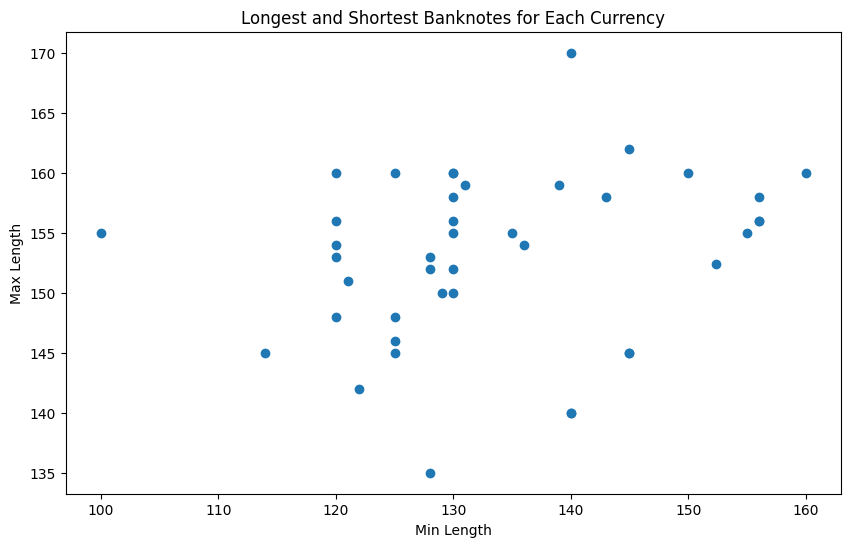

In [28]:
plt.figure(figsize=(10, 6))  
plt.scatter(length['min'], length['max'])
plt.xlabel('Min Length')
plt.ylabel('Max Length')
plt.title('Longest and Shortest Banknotes for Each Currency')
# add_labels(length, 'min' , 'max', 'currency')
plt.show()

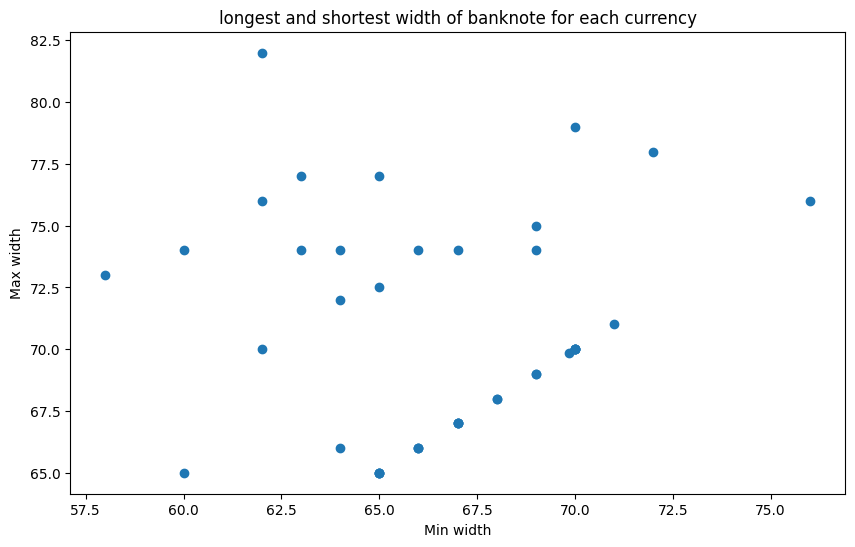

In [29]:
plt.figure(figsize=(10, 6))
plt.scatter(width['min'], width['max'])
plt.xlabel('Min width')
plt.ylabel('Max width')
plt.title("longest and shortest width of banknote for each currency")
# add_labels(width, 'min' , 'max', 'currency')
plt.show()

In [32]:
dim_summary = df.groupby('currency').agg(unique_lengths = ('length', 'nunique'), unique_widths=('width', 'nunique')).reset_index()

dim_summary.head()

,currency,unique_lengths,unique_widths
0,Argentine Peso,1,1
1,Australian Dollar,7,3
2,Bangladeshi Taka,8,2
3,Bolivian Boliviano,1,1
4,Canadian Dollar,1,1


In [40]:
def categorize_currency(row):
    len_varies = row['unique_lengths']>1
    wid_varies = row['unique_widths'] >1
    
    if len_varies and wid_varies:
        return "both length and width vary"
    elif len_varies and not wid_varies:
        return "only length varies"
    elif wid_varies and not len_varies:
        return "only width varies"
    else:
        return "No changes! All dimensions are identical"

dim_summary['category'] = dim_summary.apply(categorize_currency, axis=1)

# percentage calculation
category_counts = dim_summary['category'].value_counts()
category_pcts = (category_counts/len(dim_summary))*100

print("Percentage Breakdown by Currency Dimension Consistency:\n")
print(category_pcts.round(2).astype(str) + '%')

Percentage Breakdown by Currency Dimension Consistency:

both length and width vary                  45.24%
only length varies                          33.33%
No changes! All dimensions are identical    21.43%
Name: category, dtype: object


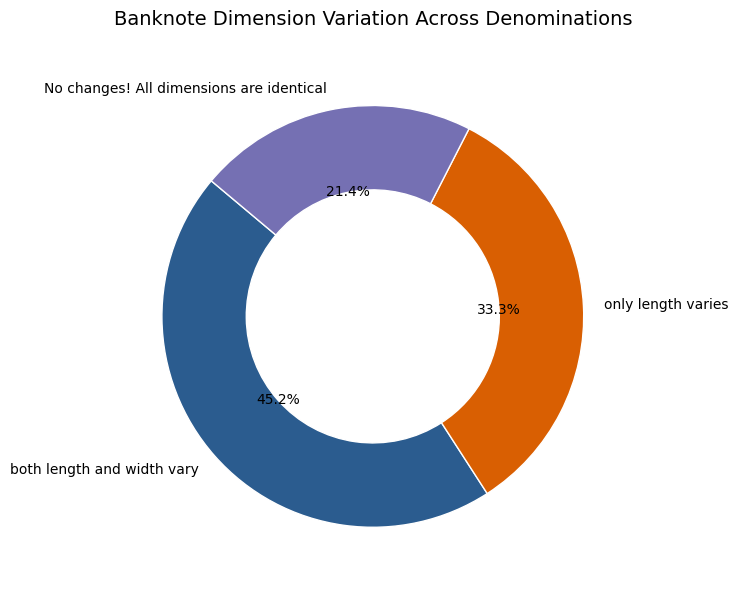

In [43]:
# Visualize findings
plt.figure(figsize=(8, 6))
colors = ['#2b5c8f', '#d95f02', '#7570b3', '#e7298a']
plt.pie(category_counts, labels=category_counts.index, autopct='%1.1f%%', 
        startangle=140, colors=colors, wedgeprops=dict(width=0.4, edgecolor='w'))
plt.title('Banknote Dimension Variation Across Denominations', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

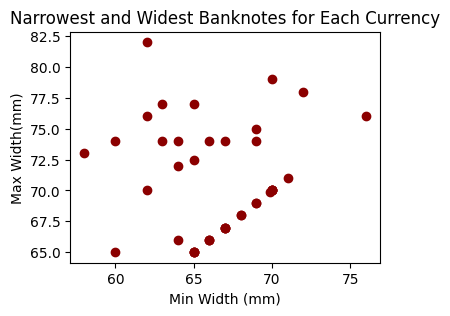

In [38]:
# width paired scatter plot with labels

plt.figure(figsize=(4,3))
plt.scatter(width['min'], width['max'], color='darkred')
plt.xlabel('Min Width (mm)')
plt.ylabel('Max Width(mm)')
plt.title("Narrowest and Widest Banknotes for Each Currency")
plt.show()

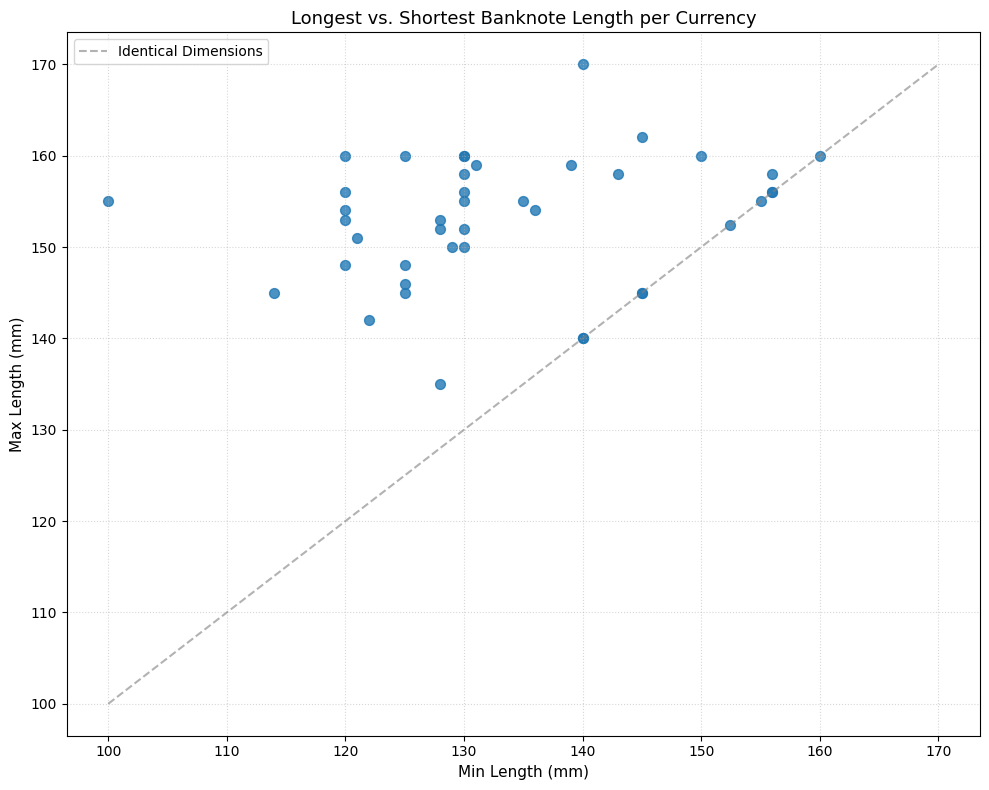

In [56]:
plt.figure(figsize=(10, 8))
plt.scatter(length['min'], length['max'], color='#1f77b4', s=50, alpha=0.8)

# Equality line (where min length equals max length)
plt.plot([df['length'].min(), df['length'].max()], [df['length'].min(), df['length'].max()], 
         color='gray', linestyle='--', alpha=0.6, label='Identical Dimensions')

plt.xlabel('Min Length (mm)', fontsize=11)
plt.ylabel('Max Length (mm)', fontsize=11)
plt.title('Longest vs. Shortest Banknote Length per Currency', fontsize=13)

plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

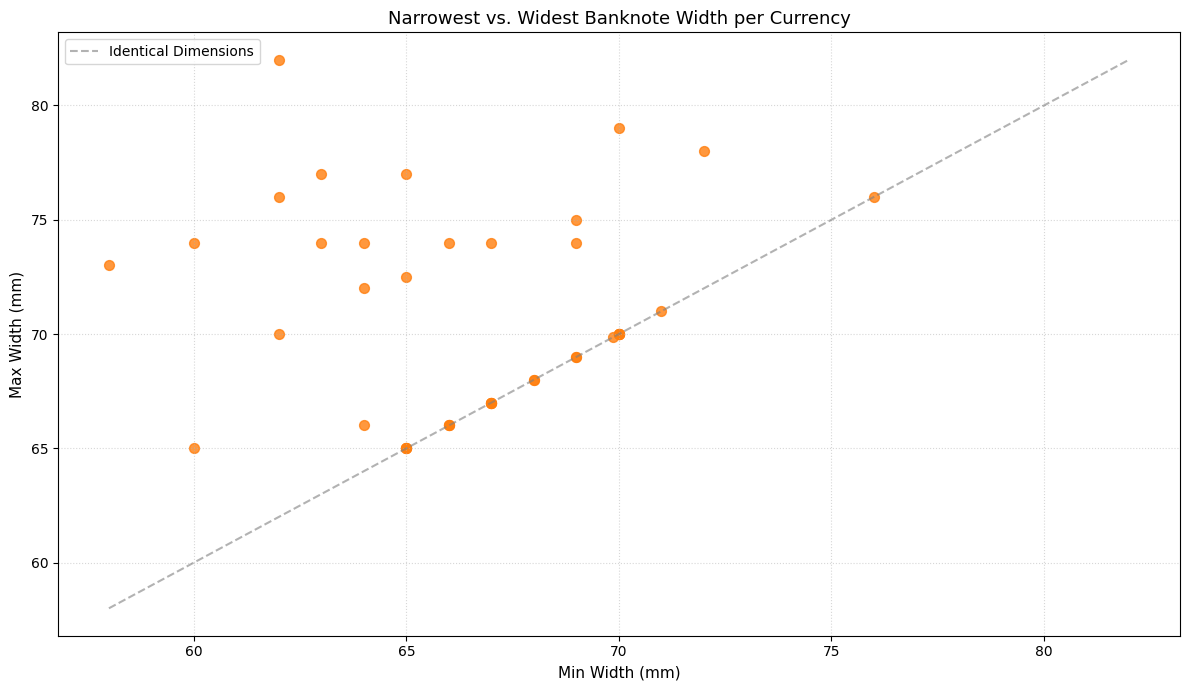

In [48]:
plt.figure(figsize=(12, 7))
plt.scatter(width['min'], width['max'], color='#ff7f0e', s=50, alpha=0.8)

# Equality line (where min width equals max width)
plt.plot([df['width'].min(), df['width'].max()], [df['width'].min(), df['width'].max()], 
         color='gray', linestyle='--', alpha=0.6, label='Identical Dimensions')

plt.xlabel('Min Width (mm)', fontsize=11)
plt.ylabel('Max Width (mm)', fontsize=11)
plt.title('Narrowest vs. Widest Banknote Width per Currency', fontsize=13)

plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

## Key Findings & Summary

1. **Dimension Variation Breakdown**:
   - **45.2%** of currencies vary **both length and width** across denominations.
   - **33.3%** vary **only length** while keeping width fixed.
   - **21.4%** maintain **identical dimensions** across all denominations.
   - **0.0%** vary only width without varying length.

2. **Design Takeaways**:
   - **Length is the preferred visual/tactile differentiator**: Currencies that differentiate denominations prefer varying length over width to maintain stackability and wallet fit.
   - **Machine Compatibility**: Currencies with uniform dimensions prioritize ATM reliability and manufacturing standardization over physical tactile cues.